In [ ]:
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

Mounted at /content/gdrive


In [ ]:
import pandas as pd

In [ ]:
DATASET_PATH = "gdrive/My Drive/Documents/Master 2026-2027/Block 1a/Network Security Analytics/Lab/datasets/"

/tmp/ipykernel_6227/2287453797.py:14: DtypeWarning: Columns (0,1,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.concat((pd.read_csv(f"{DATASET_PATH}{dataset}") for dataset in datasets), ignore_index=True)


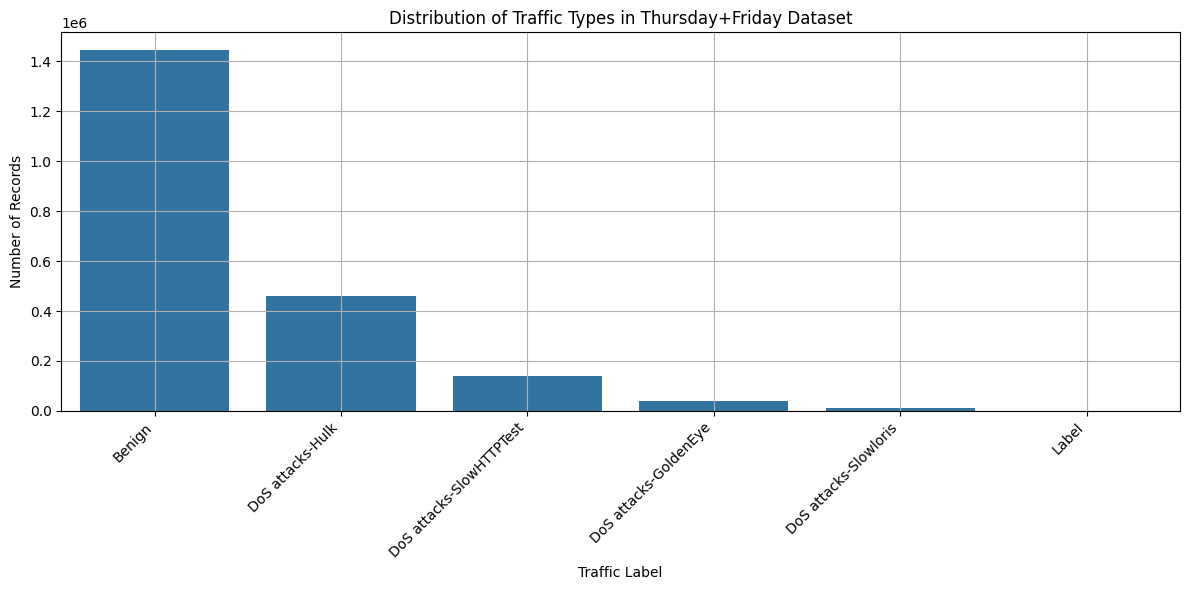

Label
Benign                      1442849
DoS attacks-Hulk             461912
DoS attacks-SlowHTTPTest     139890
DoS attacks-GoldenEye         41508
DoS attacks-Slowloris         10990
Label                             1
Name: count, dtype: int64


In [ ]:
#CELL 1


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

datasets = [
    "Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv",
    "Friday-16-02-2018_TrafficForML_CICFlowMeter.csv"
]


df = pd.concat((pd.read_csv(f"{DATASET_PATH}{dataset}") for dataset in datasets), ignore_index=True)

#clean column name if needed
df.columns = df.columns.str.strip()

#clean label values
df['Label'] = df['Label'].str.strip()

#get distribution
label_counts = df['Label'].value_counts()

#plot
plt.figure(figsize=(12, 6))
sns.barplot(x=label_counts.index, y=label_counts.values)
plt.xticks(rotation=45, ha='right')
plt.title("Distribution of Traffic Types in Thursday+Friday Dataset")
plt.xlabel("Traffic Label")
plt.ylabel("Number of Records")
plt.grid(True)
plt.tight_layout()
plt.show()

#shows class ratios
print(label_counts)


### Step 1: Data Cleaning
We will remove any redundant header rows, convert feature columns to numeric types, and handle potential missing or infinite values.

In [ ]:
import numpy as np
import gc

# 1. Filter out the header rows in-place on 'df' to avoid duplicating
df = df[df['Label'] != 'Label']

# 2. Identify metadata columns
metadata_cols = ['Timestamp']
features = [col for col in df.columns if col not in ['Label'] + metadata_cols]

# 3. Force convert features to numeric in-place (without downcasting to float32)
for col in features:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 4. Handle Infinity and NaN values in-place
df[features] = df[features].replace([np.inf, -np.inf], np.nan)

# Impute NaN values with the median of each column
for col in features:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)

print("Data cleaning complete with in-place memory optimization!")
print(f"DataFrame shape: {df.shape}")
df.info(memory_usage='deep')

Data cleaning complete with in-place memory optimization!
DataFrame shape: (2097149, 80)
<class 'pandas.core.frame.DataFrame'>
Index: 2097149 entries, 0 to 2097149
Data columns (total 80 columns):
 #   Column             Dtype  
---  ------             -----  
 0   Dst Port           int64  
 1   Protocol           int64  
 2   Timestamp          object 
 3   Flow Duration      int64  
 4   Tot Fwd Pkts       int64  
 5   Tot Bwd Pkts       int64  
 6   TotLen Fwd Pkts    int64  
 7   TotLen Bwd Pkts    int64  
 8   Fwd Pkt Len Max    int64  
 9   Fwd Pkt Len Min    int64  
 10  Fwd Pkt Len Mean   float64
 11  Fwd Pkt Len Std    float64
 12  Bwd Pkt Len Max    int64  
 13  Bwd Pkt Len Min    int64  
 14  Bwd Pkt Len Mean   float64
 15  Bwd Pkt Len Std    float64
 16  Flow Byts/s        float64
 17  Flow Pkts/s        float64
 18  Flow IAT Mean      float64
 19  Flow IAT Std       float64
 20  Flow IAT Max       int64  
 21  Flow IAT Min       int64  
 22  Fwd IAT Tot        int64  
 23

### Step 2: Feature Scaling & Label Encoding
Neural networks converge much faster and perform significantly better when features are scaled (e.g., Mean=0, Std=1). We will also encode our categorical attack labels into integers.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from tensorflow.keras.utils import to_categorical

# Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df['Label'])
num_classes = len(label_encoder.classes_)
y_categorical = to_categorical(y_encoded, num_classes=num_classes)

# Extract features
X = df[features].values

# Split into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_categorical, test_size=0.2, random_state=42, stratify=y_encoded)

# Scale features based on training distribution
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data preparation complete!")
print(f"X_train shape: {X_train_scaled.shape}, X_test shape: {X_test_scaled.shape}")
print("Classes mapped:", dict(zip(label_encoder.classes_, range(num_classes))))

Data preparation complete!
X_train shape: (1677719, 78), X_test shape: (419430, 78)
Classes mapped: {'Benign': 0, 'DoS attacks-GoldenEye': 1, 'DoS attacks-Hulk': 2, 'DoS attacks-SlowHTTPTest': 3, 'DoS attacks-Slowloris': 4}


### Step 3: Build and Train the Neural Network
Now we design a Deep Neural Network (DNN) with Dropout layers to prevent overfitting and train it on the processed dataset.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Build Multi-layer Perceptron Neural Network
model = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train the model
history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=2048,
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,509 (84.02 KB)

 Trainable params: 21,061 (82.27 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/10
738/738 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.9830 - loss: 0.0821 - val_accuracy: 0.9994 - val_loss: 0.0030
Epoch 2/10
738/738 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.9992 - loss: 0.0041 - val_accuracy: 0.9996 - val_loss: 0.0016
Epoch 3/10
738/738 ━━━━━━━━━━━━━━━━━━━━ 24s 32ms/step - accuracy: 0.9995 - loss: 0.0025 - val_accuracy: 0.9997 - val_loss: 0.0012
Epoch 4/10
738/738 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - accuracy: 0.9996 - loss: 0.0019 - val_accuracy: 0.9997 - val_loss: 9.1816e-04
Epoch 5/10
738/738 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - accuracy: 0.9996 - loss: 0.0016 - val_accuracy: 0.9997 - val_loss: 0.0011
Epoch 6/10
738/738 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.9997 - loss: 0.0013 - val_accuracy: 0.9999 - val_loss: 6.8072e-04
Epoch 7/10
738/738 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - accuracy: 0.9997 - loss: 0.0012 - val_accuracy: 0.9999 - val_loss: 5.9097e-04
Epoch 8/10
738/738 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - accuracy: 0.9997 - los

### Step 4: Evaluate the Model
We will evaluate the trained network on the unseen test dataset and look at its loss and accuracy.

In [ ]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=1)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

13108/13108 ━━━━━━━━━━━━━━━━━━━━ 28s 2ms/step - accuracy: 0.9999 - loss: 5.9378e-04

Test Loss: 0.0006
Test Accuracy: 0.9999
